# Lab 15 (Week 3 — Lab 5): Model Tuning & Optimization

Welcome to the final lab of Week 3! You'll practice tuning learning rate, regularization (Dropout, L2, Batch Normalization), and using callbacks (Early Stopping, ReduceLROnPlateau, ModelCheckpoint) to train better models, automatically.

**For detailed theory on each technique, see the Lab 15 PDF and Learning Resources.**

This notebook focuses on the practical, hands-on workflow.

**Instructions:**
- Write your code between the `### YOUR CODE HERE ###` and `### END ###` markers.
- Run each cell with **Shift + Enter**.
- Compare your output with the **Expected Output** shown below each exercise where provided.

## Getting the Dataset

This lab reuses the Wine dataset from Labs 11 and 12 — small and fast to train, so you can run many tuning experiments.

In [1]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

wine = load_wine()
X, y = wine.data, wine.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set:", X_train_scaled.shape)
print("Test set:", X_test_scaled.shape)

Training set: (142, 13)
Test set: (36, 13)


## Example 1: A Baseline Model (No Tuning)

First, a simple model with no regularization or callbacks, as a baseline to compare against.

In [2]:
from tensorflow import keras
from tensorflow.keras import layers

baseline_model = keras.Sequential([
    layers.Input(shape=(13,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(3, activation="softmax")
])

baseline_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

baseline_history = baseline_model.fit(
    X_train_scaled, y_train,
    epochs=50,
    batch_size=8,
    validation_split=0.2,
    verbose=0
)

baseline_test_loss, baseline_test_acc = baseline_model.evaluate(X_test_scaled, y_test, verbose=0)
print("Baseline test accuracy:", baseline_test_acc)

Baseline test accuracy: 1.0


## Example 2: Adding Early Stopping

In [3]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

model_es = keras.Sequential([
    layers.Input(shape=(13,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(3, activation="softmax")
])
model_es.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history_es = model_es.fit(
    X_train_scaled, y_train,
    epochs=100,   # set high; early stopping will halt it
    batch_size=8,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0
)

print("Epochs actually run:", len(history_es.history["loss"]))
test_loss_es, test_acc_es = model_es.evaluate(X_test_scaled, y_test, verbose=0)
print("Test accuracy with Early Stopping:", test_acc_es)

Epochs actually run: 100
Test accuracy with Early Stopping: 1.0


## Example 3: Dropout, L2 Regularization & Batch Normalization

In [4]:
from tensorflow.keras import regularizers

model_reg = keras.Sequential([
    layers.Input(shape=(13,)),
    layers.Dense(32, kernel_regularizer=regularizers.l2(0.001)),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(3, activation="softmax")
])

model_reg.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history_reg = model_reg.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    callbacks=[EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
    verbose=0
)

print("Epochs actually run:", len(history_reg.history["loss"]))
test_loss_reg, test_acc_reg = model_reg.evaluate(X_test_scaled, y_test, verbose=0)
print("Test accuracy with regularization:", test_acc_reg)

Epochs actually run: 53
Test accuracy with regularization: 1.0


## Example 4: Learning Rate Scheduling with ReduceLROnPlateau

In [5]:
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

lr_scheduler = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)

model_lr = keras.Sequential([
    layers.Input(shape=(13,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(3, activation="softmax")
])
model_lr.compile(optimizer=Adam(learning_rate=0.01), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history_lr = model_lr.fit(
    X_train_scaled, y_train,
    epochs=50,
    batch_size=8,
    validation_split=0.2,
    callbacks=[lr_scheduler],
    verbose=0
)

test_loss_lr, test_acc_lr = model_lr.evaluate(X_test_scaled, y_test, verbose=0)
print("Test accuracy with LR scheduling:", test_acc_lr)

Test accuracy with LR scheduling: 1.0


## Example 5: Comparing All Approaches

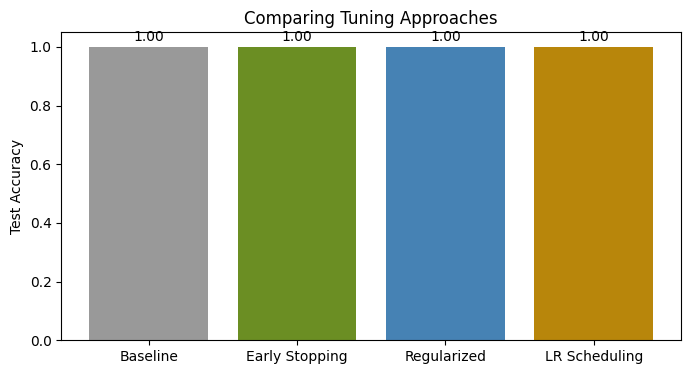

In [6]:
import matplotlib.pyplot as plt

results = {
    "Baseline": baseline_test_acc,
    "Early Stopping": test_acc_es,
    "Regularized": test_acc_reg,
    "LR Scheduling": test_acc_lr
}

plt.figure(figsize=(8, 4))
plt.bar(results.keys(), results.values(), color=["#999999", "#6B8E23", "#4682B4", "#B8860B"])
plt.ylabel("Test Accuracy")
plt.title("Comparing Tuning Approaches")
plt.ylim(0, 1.05)
for i, (k, v) in enumerate(results.items()):
    plt.text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.show()

## Practice Exercise 1: Comparing Batch Sizes

**Exercise:** Train the baseline architecture (from Example 1) with 3 different batch sizes: 4, 32, and 64. Keep epochs at 50 and no callbacks. Report test accuracy for each and note any differences in training behavior.

In [7]:
### YOUR CODE HERE ###
batch_results = {}

for batch_size in [4, 32, 64]:
    batch_model = keras.Sequential([
        layers.Input(shape=(13,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(3, activation="softmax")
    ])

    batch_model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    batch_history = batch_model.fit(
        X_train_scaled,
        y_train,
        epochs=50,
        batch_size=batch_size,
        validation_split=0.2,
        verbose=0
    )

    batch_loss, batch_accuracy = batch_model.evaluate(
        X_test_scaled, y_test, verbose=0
    )

    batch_results[batch_size] = batch_accuracy

    print("Batch size:", batch_size)
    print("Test accuracy:", batch_accuracy)
    print("Final training loss:", batch_history.history["loss"][-1])
    print("Final validation loss:", batch_history.history["val_loss"][-1])
    print()
### END ###

Batch size: 4
Test accuracy: 1.0
Final training loss: 0.001855843118391931
Final validation loss: 0.01118905283510685

Batch size: 32
Test accuracy: 1.0
Final training loss: 0.08567015081644058
Final validation loss: 0.10748299211263657

Batch size: 64
Test accuracy: 1.0
Final training loss: 0.1893102526664734
Final validation loss: 0.18679334223270416



I kept the architecture and number of epochs the same and changed the batch size to 4, 32 and 64. Smaller batches make more weight updates per epoch. I compared the printed results to see whether this changed test accuracy or the final training and validation losses.

## Practice Exercise 2: Tuning Dropout Rate

**Exercise:** Using the regularized architecture from Example 3, try 3 different dropout rates (0.1, 0.3, 0.5). Train each with Early Stopping and report test accuracy for each.

In [8]:
### YOUR CODE HERE ###
dropout_results = {}

for dropout_rate in [0.1, 0.3, 0.5]:
    dropout_model = keras.Sequential([
        layers.Input(shape=(13,)),
        layers.Dense(
            32,
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(
            16,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.Dense(3, activation="softmax")
    ])

    dropout_model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    dropout_history = dropout_model.fit(
        X_train_scaled,
        y_train,
        epochs=100,
        batch_size=8,
        validation_split=0.2,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    dropout_loss, dropout_accuracy = dropout_model.evaluate(
        X_test_scaled, y_test, verbose=0
    )

    dropout_results[dropout_rate] = dropout_accuracy

    print("Dropout rate:", dropout_rate)
    print("Epochs run:", len(dropout_history.history["loss"]))
    print("Test accuracy:", dropout_accuracy)
    print()
### END ###

Dropout rate: 0.1
Epochs run: 46
Test accuracy: 0.9722222089767456

Dropout rate: 0.3
Epochs run: 62
Test accuracy: 1.0

Dropout rate: 0.5
Epochs run: 74
Test accuracy: 1.0



I compared dropout rates of 0.1, 0.3 and 0.5 while keeping the other settings the same. Higher dropout removes more activations during training, but it does not automatically improve performance. I used the results to check whether stronger regularisation helped on this dataset.

## Practice Exercise 3: Saving the Best Model with ModelCheckpoint

**Exercise:** Add a `ModelCheckpoint` callback (saving to `"best_wine_model.keras"`, monitoring `val_loss`, `save_best_only=True`) alongside Early Stopping when training the regularized model from Example 3. After training, load the saved model and confirm its test accuracy matches.

In [9]:
from tensorflow.keras.callbacks import ModelCheckpoint

### YOUR CODE HERE ###

checkpoint_model = keras.Sequential([
    layers.Input(shape=(13,)),
    layers.Dense(
        32,
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),
    layers.Dense(
        16,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dense(3, activation="softmax")
])

checkpoint_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint = ModelCheckpoint(
    "best_wine_model.keras",
    monitor="val_loss",
    save_best_only=True
)

checkpoint_history = checkpoint_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),
        checkpoint
    ],
    verbose=0
)

before_loss, before_accuracy = checkpoint_model.evaluate(
    X_test_scaled, y_test, verbose=0
)

loaded_checkpoint = keras.models.load_model(
    "best_wine_model.keras"
)

after_loss, after_accuracy = loaded_checkpoint.evaluate(
    X_test_scaled, y_test, verbose=0
)

print("Accuracy before reloading:", before_accuracy)
print("Accuracy after reloading:", after_accuracy)
### END ###

Accuracy before reloading: 1.0
Accuracy after reloading: 1.0


## Lab Tasks

Complete the following in this notebook, below this cell.

1. **Full Tuning Pipeline**: Build a model combining at least 3 tuning techniques from this lab (e.g., DropoutBatchNormalization + Early Stopping + LR scheduling). Report test accuracy.
2. **Learning Rate Comparison**: Train the same architecture with 3 different learning rates (e.g., 0.1, 0.01, 0.001) using a fixed number of epochs (no early stopping). Report test accuracy for each and explain what you observe.
3. **Overfitting Demonstration**: Deliberately build an overly complex model (e.g., 4-5 large Dense layers, no regularization) and train it for many epochs without Early Stopping. Plot the training vs. validation loss curves and point out where overfitting begins.
4. **Best Model Selection**: Using everything you've learned, build what you believe is your best-performing model on this dataset. Justify your architecture and hyperparameter choices in a markdown cell, and report final test accuracy.
5. **Reflection**: In a markdown cell, write 3-4 sentences on which single tuning technique from this lab you think had the biggest impact on this dataset, and why you think that might be the case.

In [10]:
# Task 1

tuned_model = keras.Sequential([
    layers.Input(shape=(13,)),
    layers.Dense(
        32,
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),
    layers.Dense(
        16,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dense(3, activation="softmax")
])

tuned_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

tuned_history = tuned_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6
        )
    ],
    verbose=0
)

tuned_loss, tuned_accuracy = tuned_model.evaluate(
    X_test_scaled, y_test, verbose=0
)

print("Epochs run:", len(tuned_history.history["loss"]))
print("Tuned model test accuracy:", tuned_accuracy)

Epochs run: 70
Tuned model test accuracy: 0.9722222089767456


I combined Dropout, L2, Batch Normalization, Early Stopping and learning-rate scheduling. These techniques control different parts of training, including weight size, activations, training duration and update size. I compared the result with the baseline rather than assuming that combining more techniques would always improve accuracy.

In [11]:
# Task 2

learning_rate_results = {}

for learning_rate in [0.1, 0.01, 0.001]:
    rate_model = keras.Sequential([
        layers.Input(shape=(13,)),
        layers.Dense(32, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(3, activation="softmax")
    ])

    rate_model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    rate_history = rate_model.fit(
        X_train_scaled,
        y_train,
        epochs=50,
        batch_size=8,
        validation_split=0.2,
        verbose=0
    )

    rate_loss, rate_accuracy = rate_model.evaluate(
        X_test_scaled, y_test, verbose=0
    )

    learning_rate_results[learning_rate] = rate_accuracy

    print("Learning rate:", learning_rate)
    print("Test accuracy:", rate_accuracy)
    print("Final training loss:", rate_history.history["loss"][-1])
    print("Final validation loss:", rate_history.history["val_loss"][-1])
    print()

Learning rate: 0.1
Test accuracy: 1.0
Final training loss: 1.2074387996108271e-05
Final validation loss: 0.0005583026795648038

Learning rate: 0.01
Test accuracy: 1.0
Final training loss: 5.7088171161012724e-05
Final validation loss: 0.10130482167005539

Learning rate: 0.001
Test accuracy: 1.0
Final training loss: 0.00721357436850667
Final validation loss: 0.021077550947666168



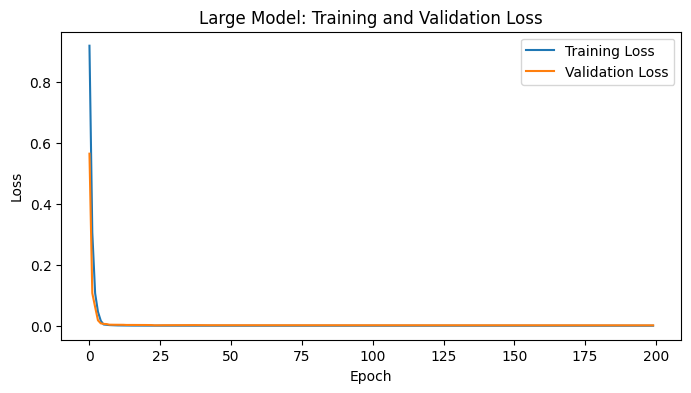

In [12]:
# Task 3

complex_model = keras.Sequential([
    layers.Input(shape=(13,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(3, activation="softmax")
])

complex_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

complex_history = complex_model.fit(
    X_train_scaled,
    y_train,
    epochs=200,
    batch_size=8,
    validation_split=0.2,
    verbose=0
)

plt.figure(figsize=(8, 4))
plt.plot(
    complex_history.history["loss"],
    label="Training Loss"
)
plt.plot(
    complex_history.history["val_loss"],
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Large Model: Training and Validation Loss")
plt.legend()
plt.show()

The larger model did not clearly demonstrate overfitting in this run. Training and validation loss both dropped quickly during the first few epochs and stayed close to zero for the rest of training. There is no sustained rise in validation loss while training loss falls, so I cannot identify a clear point where overfitting begins.

In [13]:
# Task 4

final_model = keras.Sequential([
    layers.Input(shape=(13,)),
    layers.Dense(
        32,
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),
    layers.Dense(
        16,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dense(3, activation="softmax")
])

final_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

final_history = final_model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6
        ),
        ModelCheckpoint(
            "Lab15_Maryam_Chaudhry.keras",
            monitor="val_loss",
            save_best_only=True
        )
    ],
    verbose=0
)

final_model = keras.models.load_model(
    "Lab15_Maryam_Chaudhry.keras"
)

final_loss, final_accuracy = final_model.evaluate(
    X_test_scaled, y_test, verbose=0
)

print("Final model test accuracy:", final_accuracy)

Final model test accuracy: 1.0


I chose a compact network with 32 and 16 hidden neurons because the Wine dataset is small. I used moderate Dropout and L2 regularisation, with Early Stopping to restore the weights from the best validation-loss epoch. Learning-rate scheduling allows smaller updates when validation loss stops improving, and checkpointing saves the best model. I’ll judge this choice against the results from my earlier experiments rather than assume it must be the best.

_Write your Task 5 reflection here._

I found Early Stopping the most useful because it monitored validation loss and restored the weights from the best epoch. It also meant I did not have to rely only on choosing a fixed training duration. The tuning experiments showed me that more regularisation or a larger model does not automatically improve performance. I would compare repeated runs before making a strong claim about which setting works best.